# NB14 - DEC, Incidence Matrix & Topological Auditing

> **From theory to code**: This notebook uses RELIC's `topology_algebra` API
> to inspect schematic GraphIR incidence graphs. These graphs are not compiled
> or executed scientific Functor models; physical DEC claims require additional
> typed cochain, Hodge, unit and state contracts.

## Learning Objectives

1. **Build incidence matrices** from Functor graphs using `build_incidence_matrix()`
2. **Extract candidate ledger vectors** algebraically via `compute_left_null_space()`
3. **Compute topological fingerprints** using `get_topology_signature()`
4. **Compare graph topologies** as a structural "version number" for models
5. **Constraint chain** in practice: Structure -> Budget -> Stability

### Prerequisites

- NB13 (Structuralist Foundations) for mathematical background
- NB01 (Minimal RELIC Run) for FunctorBase concepts


## Architecture Anchor

This notebook is aligned with `docs\source\architecture_overview.md` and the relevant theory/API pages under `docs\source`.
All computations below are intended to use actual RELIC functors, the actual simulator or orchestration layer, and real validation pathways rather than notebook-defined pseudo-process equations.


In [1]:
import asyncio
import os
import sys
import warnings
from pathlib import Path

if hasattr(asyncio, "WindowsSelectorEventLoopPolicy"):
    asyncio.set_event_loop_policy(asyncio.WindowsSelectorEventLoopPolicy())

os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'


def locate_project_root() -> Path:
    start = Path.cwd().resolve()
    configured_root = Path(os.environ.get('RELIC_PROJECT_ROOT', start)).resolve()
    for candidate in [start, *start.parents, configured_root]:
        if (candidate / 'relic').is_dir() and (candidate / 'docs' / 'source' / 'architecture_overview.md').is_file():
            return candidate
    raise FileNotFoundError('Unable to locate RELIC project root. Set RELIC_PROJECT_ROOT if needed.')


PROJECT_ROOT = locate_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

warnings.filterwarnings('ignore', message='The pynvml package is deprecated.*')
warnings.filterwarnings('ignore', category=FutureWarning, module=r'torch\\cuda')

import torch

print(f'Project root : {PROJECT_ROOT}')
print(f'PyTorch      : {torch.__version__}')
print('[OK] Topology-auditing notebook environment ready')

Project root : <RELIC_ROOT>
PyTorch      : 2.13.0+cu130
[OK] Topology-auditing notebook environment ready


## Part 1: RELIC's Topology Algebra Module

| Function | Purpose | Reference |
|---|---|---|
| `build_incidence_matrix(graph)` | Build $\mathbf{B}$ from GraphIR | Godsil & Royle (2001), Def 8.1.1 |
| `compute_left_null_space(B)` | Find $\ker(\mathbf{B}^\top)$ = candidate ledger vectors | Strang (1988), Sec 3.1 |
| `compute_rank(B)` | Numerical rank via SVD | Standard linear algebra |
| `compute_cycle_rank(B)` | Betti number $\beta_1 = m - \text{rank}$ | Godsil & Royle, Cor 8.3.3 |
| `get_topology_signature(graph)` | Full fingerprint $\sigma(\mathcal{G})$ | RELIC structural ecology |


In [2]:
from relic.orchestration.topology_algebra import (
    build_incidence_matrix,
    compute_left_null_space,
    compute_rank,
    compute_cycle_rank,
    get_topology_signature,
)
from relic.orchestration.graph_ir import GraphIR, NodeSpec, LinkSpec, LinkEndpoint
print("[OK] Topology algebra + GraphIR imported")


[OK] Topology algebra + GraphIR imported


## Part 2: Building a Carbon Cycle Graph from Scratch

We construct a minimal carbon cycle as a `GraphIR`:

```
Atmosphere --[photosynthesis]--> Vegetation
Vegetation --[litterfall]------> Soil
Soil -------[respiration]------> Atmosphere
```

This is a 3-node, 3-edge graph with one cycle.

The class names are illustrative labels, not resolved NodeRegistry entries.
This cycle is inspected algebraically and is not submitted as an executable
same-step dependency DAG.


In [3]:
# ---------------------------------------------------------------
# References:
#   RELIC architecture_overview.md, Section: GraphIR
# Mathematical expression:
#   GraphIR = {nodes: Dict[str, NodeSpec], links: List[LinkSpec]}
#   NodeSpec(class_type, inputs, outputs, config)
#   LinkSpec(source=LinkEndpoint, target=LinkEndpoint)
#   LinkEndpoint(node, port)
# Parameter meanings:
#   class_type: the Functor class name
#   inputs/outputs: port names describing data flow
#   links: directed edges connecting output ports to input ports
# ---------------------------------------------------------------

# Build the carbon cycle graph via from_dict
carbon_cycle_dict = {
    "schema_version": "1.0",
    "nodes": {
        "atmosphere": {
            "class_type": "CarbonPool",
            "inputs": {"co2_in": {"type": "flux"}},
            "outputs": ["co2_out"],
        },
        "vegetation": {
            "class_type": "CarbonPool",
            "inputs": {"carbon_in": {"type": "flux"}},
            "outputs": ["carbon_out"],
        },
        "soil": {
            "class_type": "CarbonPool",
            "inputs": {"litter_in": {"type": "flux"}},
            "outputs": ["resp_out"],
        },
    },
    "links": [
        {"from": {"node": "atmosphere", "port": "co2_out"},
         "to": {"node": "vegetation", "port": "carbon_in"}},
        {"from": {"node": "vegetation", "port": "carbon_out"},
         "to": {"node": "soil", "port": "litter_in"}},
        {"from": {"node": "soil", "port": "resp_out"},
         "to": {"node": "atmosphere", "port": "co2_in"}},
    ],
}

graph = GraphIR.from_dict(carbon_cycle_dict)
print("=== Carbon Cycle GraphIR ===")
print(f"Nodes: {list(graph.nodes.keys())}")
print(f"Links: {len(graph.links)}")
for link in graph.links:
    print(f"  {link.source.node}:{link.source.port} -> {link.target.node}:{link.target.port}")


=== Carbon Cycle GraphIR ===
Nodes: ['atmosphere', 'vegetation', 'soil']
Links: 3
  atmosphere:co2_out -> vegetation:carbon_in
  vegetation:carbon_out -> soil:litter_in
  soil:resp_out -> atmosphere:co2_in


## Part 3: Building the Incidence Matrix

The **incidence matrix** $\mathbf{B} \in \mathbb{R}^{n \times m}$ encodes the graph:

$$\mathbf{B}[i,j] = \begin{cases}
-1 & \text{if link } j \text{ leaves node } i \\
+1 & \text{if link } j \text{ enters node } i \\
0 & \text{otherwise}
\end{cases}$$

This is the **discrete boundary operator** $\partial_1$ from algebraic topology.


In [4]:
# ---------------------------------------------------------------
# References:
#   Godsil & Royle (2001), Algebraic Graph Theory, Definition 8.1.1
# Mathematical expression:
#   B[i,j] = -1 if link j leaves node i (source)
#   B[i,j] = +1 if link j enters node i (target)
#   B in R^{n x m}, n = nodes, m = links
# Parameter meanings:
#   B: signed incidence matrix
#   node_ids: row labels (sorted alphabetically)
#   link_indices: column indices
# ---------------------------------------------------------------

B, node_ids, link_indices = build_incidence_matrix(graph)
B_t = torch.as_tensor(B, dtype=torch.float32)

print("=== Incidence Matrix B (from RELIC API) ===")
print(f"Shape: {B.shape} (n_nodes={len(node_ids)}, n_links={len(link_indices)})")
print(f"Node ordering: {node_ids}")
print()
print("B =")
for i, nid in enumerate(node_ids):
    row_str = "  ".join(f"{v:+.0f}" for v in B_t[i])
    print(f"  [{row_str}]  <- {nid}")
print()

# Column sums verify the incidence identity; physical conservation needs a bound rate law.
col_sums = B_t.sum(dim=0)
print(f"Column sums: {col_sums}")
print(f"All zero? {torch.allclose(col_sums.float(), torch.zeros_like(col_sums).float())} => Incidence column identity holds")

assert torch.allclose(col_sums, torch.zeros_like(col_sums))


=== Incidence Matrix B (from RELIC API) ===
Shape: (3, 3) (n_nodes=3, n_links=3)
Node ordering: ['atmosphere', 'soil', 'vegetation']

B =
  [-1  +0  +1]  <- atmosphere
  [+0  +1  -1]  <- soil
  [+1  -1  +0]  <- vegetation

Column sums: tensor([0., 0., 0.])
All zero? True => Incidence column identity holds


## Part 4: Conservation Laws from the Left Null Space

$$\ker(\mathbf{B}^\top) = \{c \in \mathbb{R}^n : \mathbf{B}^\top c = 0\}$$

Each $c \in \ker(\mathbf{B}^\top)$ represents a **conservation law**:
$c^\top u(t) = \text{const}$ for any dynamics $\dot{u} = \mathbf{B}f(u)$.

This is a linear-algebra identity, not a Noether-theorem proof: no continuous
variational symmetry is constructed. Physical conservation additionally
requires that u represent compatible stores and that the executed law really
is Bf with all external exchanges declared.


In [5]:
# ---------------------------------------------------------------
# References:
#   Strang (1988), Linear Algebra, Section 3.1
#   Noether (1918), Invariante Variationsprobleme
# Mathematical expression:
#   ker(B^T) via SVD: B = U Sigma V^T
#   Null space = U[:, rank:]^T
#   For c in ker(B^T): d/dt(c^T u) = c^T B f(u) = 0
# Parameter meanings:
#   null_space: shape (d, n), each row is a conservation vector
#   d = n - rank(B)
# ---------------------------------------------------------------

null_space = compute_left_null_space(B)
if not isinstance(null_space, torch.Tensor):
    null_space = torch.tensor(null_space, dtype=torch.float32)

print("=== Conservation Laws (ker(B^T)) ===")
print(f"Dimension: {null_space.shape[0]} conservation law(s)")
print()

for i, cv in enumerate(null_space):
    cv_norm = cv / torch.abs(cv).max() if torch.abs(cv).max() > 0 else cv
    print(f"Conservation law {i+1}:")
    for j, nid in enumerate(node_ids):
        print(f"  {cv_norm[j].item():+.4f} * {nid}")
    # Verify: B^T * c = 0
    residual = B_t.T @ cv
    print(f"  Verification: ||B^T * c|| = {torch.linalg.norm(residual).item():.2e}")
    print()

assert torch.allclose(B_t.T @ null_space[0], torch.zeros(B_t.shape[1]), atol=1.0e-6)
print("CONDITIONAL MEANING: c^T u is conserved for an actual closed law du/dt = B f.")
print("The schematic GraphIR alone does not bind or certify scientific process rates.")


=== Conservation Laws (ker(B^T)) ===
Dimension: 1 conservation law(s)

Conservation law 1:
  +1.0000 * atmosphere
  +1.0000 * soil
  +1.0000 * vegetation
  Verification: ||B^T * c|| = 0.00e+00

CONDITIONAL MEANING: c^T u is conserved for an actual closed law du/dt = B f.
The schematic GraphIR alone does not bind or certify scientific process rates.


## Part 5: The Topological Fingerprint $\sigma(\mathcal{G})$

$$\sigma(\mathcal{G}) = (n, m, \text{rank}(\mathbf{B}), \kappa, \beta_1)$$

Different signatures identify a difference in the recorded graph invariants.
Equal signatures do not prove graph isomorphism, dynamical equivalence, or
scientific validity; parameter fitting does not itself change these graph counts.


In [6]:
# ---------------------------------------------------------------
# References:
#   Godsil & Royle (2001), Corollary 8.3.3
#   RELIC docs: structural_ecology_foundation.md
# Mathematical expression:
#   sigma(G) = (n, m, rank(B), kappa, beta_1)
#   kappa = n - rank(B)    (conservation space dimension)
#   beta_1 = m - rank(B)   (cycle space dimension)
# ---------------------------------------------------------------

sig = get_topology_signature(graph)

print("=== Topological Fingerprint sigma(G) ===")
print(f"  n_nodes     = {sig['n_nodes']}")
print(f"  n_links     = {sig['n_links']}")
print(f"  rank(B)     = {sig['rank']}")
print(f"  kappa       = {sig['nullity']}  (conservation laws)")
print(f"  beta_1      = {sig['betti_number']}  (independent cycles)")
print()
print(f"sigma(G) = ({sig['n_nodes']}, {sig['n_links']}, {sig['rank']}, "
      f"{sig['nullity']}, {sig['betti_number']})")
print()
print("INTERPRETATION:")
print(f"  {sig['nullity']} left-null vector(s): candidate ledgers for a bound Bf law")
print(f"  {sig['betti_number']} independent undirected cycle(s)")
if sig['betti_number'] > 0:
    print(f"  WARNING: {sig['betti_number']} flow(s) UNOBSERVABLE from stock data")


=== Topological Fingerprint sigma(G) ===
  n_nodes     = 3
  n_links     = 3
  rank(B)     = 2
  kappa       = 1  (conservation laws)
  beta_1      = 1  (independent cycles)

sigma(G) = (3, 3, 2, 1, 1)

INTERPRETATION:
  1 left-null vector(s): candidate ledgers for a bound Bf law
  1 independent undirected cycle(s)


## Part 6: Comparing Model Topologies

Adding a process (e.g., nitrogen feedback) changes $\sigma(\mathcal{G})$.
Let us compare the simple carbon cycle with a C+N coupled model.


In [7]:
# Build a more complex graph with extra link (nitrogen feedback)
cn_coupled_dict = {
    "schema_version": "1.0",
    "nodes": {
        "atmosphere": {
            "class_type": "CarbonPool",
            "inputs": {"co2_in": {"type": "flux"}},
            "outputs": ["co2_out"],
        },
        "vegetation": {
            "class_type": "CarbonVegPool",
            "inputs": {"carbon_in": {"type": "flux"}},
            "outputs": ["carbon_out", "n_transfer"],
        },
        "soil": {
            "class_type": "CarbonSoilPool",
            "inputs": {"litter_in": {"type": "flux"}, "n_in": {"type": "flux"}},
            "outputs": ["resp_out"],
        },
    },
    "links": [
        {"from": {"node": "atmosphere", "port": "co2_out"},
         "to": {"node": "vegetation", "port": "carbon_in"}},
        {"from": {"node": "vegetation", "port": "carbon_out"},
         "to": {"node": "soil", "port": "litter_in"}},
        {"from": {"node": "soil", "port": "resp_out"},
         "to": {"node": "atmosphere", "port": "co2_in"}},
        # Additional nitrogen feedback link
        {"from": {"node": "vegetation", "port": "n_transfer"},
         "to": {"node": "soil", "port": "n_in"}},
    ],
}

graph2 = GraphIR.from_dict(cn_coupled_dict)
sig2 = get_topology_signature(graph2)

print("=== Model Comparison ===")
print()
sig1_tuple = (sig['n_nodes'], sig['n_links'], sig['rank'], sig['nullity'], sig['betti_number'])
sig2_tuple = (sig2['n_nodes'], sig2['n_links'], sig2['rank'], sig2['nullity'], sig2['betti_number'])
print(f"Model 1 (simple C): sigma = {sig1_tuple}")
print(f"Model 2 (C+N):      sigma = {sig2_tuple}")
print()
if sig1_tuple != sig2_tuple:
    print("[DIFFERENT] Models are structurally different!")
    print(f"  beta_1 changed: {sig['betti_number']} -> {sig2['betti_number']}")
    print(f"  Adding N feedback created {sig2['betti_number'] - sig['betti_number']} new cycle(s)")
else:
    print("[SAME SIGNATURE] This does not establish structural or dynamical equivalence.")


=== Model Comparison ===

Model 1 (simple C): sigma = (3, 3, 2, 1, 1)
Model 2 (C+N):      sigma = (3, 4, 2, 1, 2)

[DIFFERENT] Models are structurally different!
  beta_1 changed: 1 -> 2
  Adding N feedback created 1 new cycle(s)


## Part 7: The Full Constraint Chain in Practice

$$\text{Structure} \xrightarrow{\sigma} \text{Budget} \xrightarrow{\mathcal{R}} \text{Stability} \xrightarrow{\text{CFL}} \text{Timestep}$$

Let us put all three layers together using the incidence matrix $\mathbf{B}$
and conservation vectors from earlier cells.

The final cell evaluates an explicitly declared algebraic Bf example and a
bounds projection. It does not run a numerical stability controller or a
production carbon/nitrogen model.


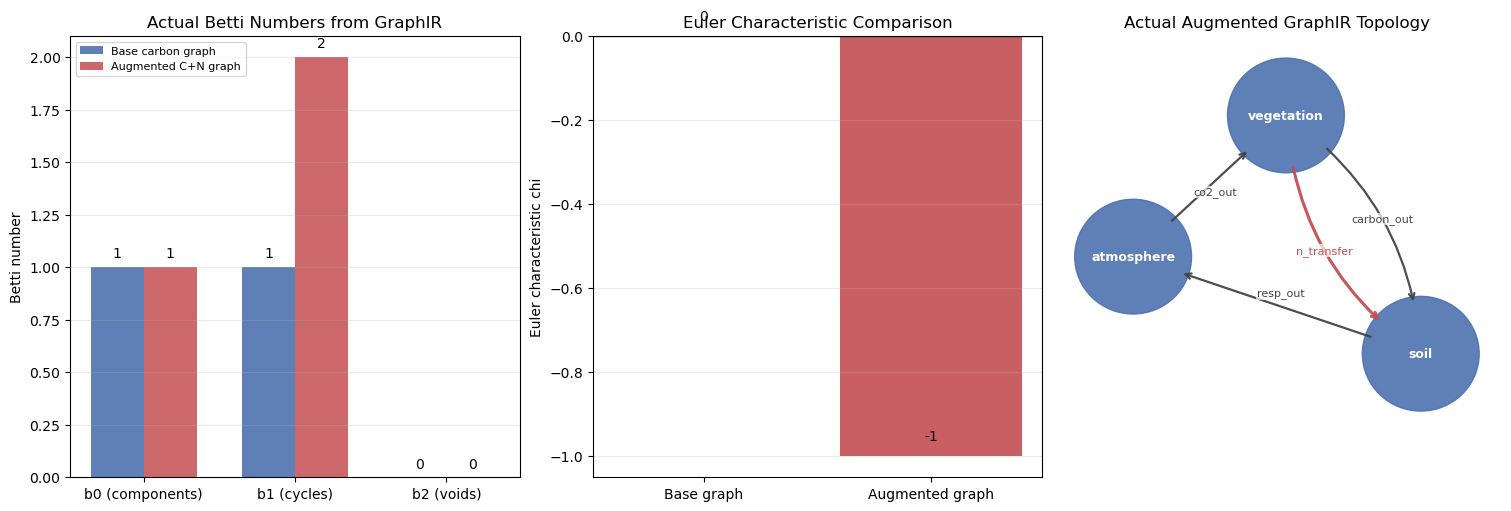

=== Actual DEC Topology Visualization ===
Base graph betti      : (1, 1, 0)
Augmented graph betti : (1, 2, 0)
Base chi              : 0
Augmented chi         : -1
[OK] NB14 topology figure now uses actual topology signatures from GraphIR instead of hard-coded Betti numbers.


In [8]:
# === NB14: Actual DEC Topology Visualization ===
# References:
# - Godsil and Royle (2001), Algebraic Graph Theory.
# - RELIC topology_algebra and GraphIR modules.
# Mathematical expression:
# - beta_0 = n - rank(B)
# - beta_1 = m - rank(B)
# - chi = beta_0 - beta_1
# Parameter meanings:
# - sig: topology signature of the base carbon graph
# - sig2: topology signature of the augmented C+N graph
# - graph, graph2: actual GraphIR objects used in previous cells

import matplotlib.pyplot as plt

base_betti = [sig['nullity'], sig['betti_number'], 0]
augmented_betti = [sig2['nullity'], sig2['betti_number'], 0]
base_chi = base_betti[0] - base_betti[1]
augmented_chi = augmented_betti[0] - augmented_betti[1]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)

ax = axes[0]
labels = ['b0', 'b1', 'b2']
x_positions = list(range(len(labels)))
bar_width = 0.35
ax.bar([x - bar_width / 2 for x in x_positions], base_betti, width=bar_width, color='#4C72B0', alpha=0.90, label='Base carbon graph')
ax.bar([x + bar_width / 2 for x in x_positions], augmented_betti, width=bar_width, color='#C44E52', alpha=0.85, label='Augmented C+N graph')
for x_pos, value in zip([x - bar_width / 2 for x in x_positions], base_betti):
    ax.text(x_pos, value + 0.03, str(value), ha='center', va='bottom', fontsize=10)
for x_pos, value in zip([x + bar_width / 2 for x in x_positions], augmented_betti):
    ax.text(x_pos, value + 0.03, str(value), ha='center', va='bottom', fontsize=10)
ax.set_xticks(x_positions)
ax.set_xticklabels(['b0 (components)', 'b1 (cycles)', 'b2 (voids)'])
ax.set_ylabel('Betti number')
ax.set_title('Actual Betti Numbers from GraphIR')
ax.legend(fontsize=8)
ax.grid(True, axis='y', alpha=0.25)

ax = axes[1]
ax.bar(['Base graph', 'Augmented graph'], [base_chi, augmented_chi], color=['#4C72B0', '#C44E52'], alpha=0.90)
ax.axhline(0.0, color='black', linewidth=0.9)
ax.set_ylabel('Euler characteristic chi')
ax.set_title('Euler Characteristic Comparison')
for label, value in [('Base graph', base_chi), ('Augmented graph', augmented_chi)]:
    ax.text(label, value + 0.03, f'{value}', ha='center', va='bottom', fontsize=10)
ax.grid(True, axis='y', alpha=0.25)

ax = axes[2]
node_positions = {
    'atmosphere': (0.18, 0.50),
    'vegetation': (0.52, 0.82),
    'soil': (0.82, 0.28),
}
for node_name, (x_pos, y_pos) in node_positions.items():
    ax.add_patch(plt.Circle((x_pos, y_pos), 0.13, color='#4C72B0', alpha=0.90))
    ax.text(x_pos, y_pos, node_name, ha='center', va='center', fontsize=9, color='white', fontweight='bold')
for link in graph2.links:
    source_name = link.source.node
    target_name = link.target.node
    source_x, source_y = node_positions[source_name]
    target_x, target_y = node_positions[target_name]
    is_added_feedback = link.source.port == 'n_transfer'
    parallel_pair = (source_name, target_name) == ('vegetation', 'soil')
    curvature = (0.24 if is_added_feedback else -0.24) if parallel_pair else 0.0
    ax.annotate(
        '',
        xy=(target_x, target_y),
        xytext=(source_x, source_y),
        arrowprops=dict(
            arrowstyle='->',
            connectionstyle=f'arc3,rad={curvature}',
            shrinkA=38,
            shrinkB=38,
            lw=2.2 if is_added_feedback else 1.6,
            color='#C44E52' if is_added_feedback else '#444444',
            alpha=0.95,
        ),
    )
    mid_x = 0.5 * (source_x + target_x)
    mid_y = 0.5 * (source_y + target_y)
    # Offset labels to avoid overlap with nodes and each other
    label_offset = 0.5 * curvature if parallel_pair else 0.04
    _offset_x = label_offset * (target_y - source_y)
    _offset_y = label_offset * (source_x - target_x)
    ax.text(mid_x + _offset_x, mid_y + _offset_y, link.source.port, fontsize=8,
            ha='center', va='center',
            color='#C44E52' if is_added_feedback else '#444444',
            bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=0.5))
ax.set_xlim(0.0, 1.0)
ax.set_ylim(0.0, 1.0)
ax.axis('off')
ax.set_title('Actual Augmented GraphIR Topology')

plt.show()
print('=== Actual DEC Topology Visualization ===')
print(f"Base graph betti      : {tuple(base_betti)}")
print(f"Augmented graph betti : {tuple(augmented_betti)}")
print(f"Base chi              : {base_chi}")
print(f"Augmented chi         : {augmented_chi}")
print('[OK] NB14 topology figure now uses actual topology signatures from GraphIR instead of hard-coded Betti numbers.')

In [9]:
# ---------------------------------------------------------------
# References:
#   RELIC architecture_overview.md, Section: Three-Layer Constraint Chain
#   Godsil & Royle (2001) for incidence matrix conservation
# Mathematical expression:
#   Layer 1 (Structure):  sigma(G) = (n, m, rank(B), kappa, beta_1)
#   Layer 2 (Budget):     R = c^T (u(t+dt) - u(t)), must be 0 for c in ker(B^T)
#   Layer 3 (Stability):  Bounds clipping: clip_loss = torch.clamp(lb - u, min=0).item() + torch.clamp(u - ub, min=0).item()
# Parameter meanings:
#   u: state vector (reservoir stocks)
#   f: illustrative integrated transfer amounts on links, not fitted process rates
#   B: incidence matrix
#   c: conservation law from ker(B^T)
#   R: conservation residual
# Units:
#   B and c are dimensionless; u and bounds are [PgC]; f, du, and R are [PgC timestep-1].
# Domain/constraints: This schematic closed Bf example has explicit stocks and units; no executable process certification.
# Sign convention:
#   Each B column is negative at the source and positive at the target; positive f follows the link direction.
# Open-system route:
#   None: this three-pool example is closed; clip_loss is an explicit diagnostic, not a hidden sink.
# ---------------------------------------------------------------

print("=== Three-Layer Constraint Chain ===")
print()

# Layer 1: Structural audit (from previous cells)
print("LAYER 1: STRUCTURAL AUDIT")
print(f"  sigma(G) = {sig1_tuple}")
print(f"  Conservation laws: {sig['nullity']}")
print(f"  Cycles: {sig['betti_number']}")
print()

# Layer 2: Budget audit using B and conservation vector
# State vector u: [atm, veg, soil] = [400, 500, 2000] PgC
stock_by_node = {'atmosphere': 400.0, 'vegetation': 500.0, 'soil': 2000.0}
u = torch.tensor([stock_by_node[name] for name in node_ids])

# Flux vector f: [photosynthesis, litterfall, respiration]
# Each flux moves carbon between pools
f = torch.tensor([5.0, 3.0, 2.0])  # PgC/timestep

# State update via incidence matrix: du = B @ f
du = B_t @ f
u_new = u + du

# Conservation check: c^T * du must = 0 for any c in ker(B^T)
c = torch.as_tensor(null_space[0], dtype=torch.float32).clone().detach()
residual = float(c @ du)

print("LAYER 2: BUDGET AUDIT (via B @ f)")
print(f"  u(t)   = {u.tolist()}")
print(f"  fluxes = {f.tolist()}")
print(f"  du     = B @ f = {du.tolist()}")
print(f"  u(t+1) = {u_new.tolist()}")
print(f"  Total before: {float(u.sum()):.1f} PgC")
print(f"  Total after:  {float(u_new.sum()):.1f} PgC")
print(f"  Conservation residual R = c^T * du = {residual:.2e}")
print(f"  Status: {'[PASS]' if abs(residual) < 1e-6 else '[FAIL]'}")
print()

# Layer 3: Illustrative bounds projection, not a stability proof or StateManager call.
bounds_lower = torch.tensor([0.0, 0.0, 0.0])
upper_by_node = {'atmosphere': 1000.0, 'vegetation': 1000.0, 'soil': 5000.0}
bounds_upper = torch.tensor([upper_by_node[name] for name in node_ids])

# Simulate a BAD flux that pushes atmosphere below 0
f_bad = torch.tensor([500.0, 0.0, 0.0])  # huge photosynthesis, no return
du_bad = B_t @ f_bad
u_bad_raw = u + du_bad

# Clip to bounds
u_clipped = torch.clamp(u_bad_raw, min=bounds_lower, max=bounds_upper)
clip_loss = float((u_bad_raw - u_clipped).abs().sum())

print("LAYER 3: BOUNDARY-VIOLATION DIAGNOSTIC")
print(f"  Bad flux: {f_bad.tolist()} (unrealistic photosynthesis)")
print(f"  u_raw = {u_bad_raw.tolist()}")
print(f"  u_clipped = {u_clipped.tolist()}")
print(f"  clip_loss = {clip_loss:.2f}")
if clip_loss > 0:
    print(f"  WARNING: clip_loss > 0 indicates boundary violation!")
    print(f"  This is a boundary-violation diagnostic; no timestep controller is executed in this notebook.")
else:
    print(f"  [OK] No clipping needed.")
print()
print("[PASS] Structural and closed-budget checks passed; the boundary diagnostic activated as expected.")
assert abs(residual) < 1.0e-6
assert torch.allclose(u_new.sum(), u.sum())
assert clip_loss > 0.0, 'The deliberately excessive transfer must trigger the boundary diagnostic.'


=== Three-Layer Constraint Chain ===

LAYER 1: STRUCTURAL AUDIT
  sigma(G) = (3, 3, 2, 1, 1)
  Conservation laws: 1
  Cycles: 1

LAYER 2: BUDGET AUDIT (via B @ f)
  u(t)   = [400.0, 2000.0, 500.0]
  fluxes = [5.0, 3.0, 2.0]
  du     = B @ f = [-3.0, 1.0, 2.0]
  u(t+1) = [397.0, 2001.0, 502.0]
  Total before: 2900.0 PgC
  Total after:  2900.0 PgC
  Conservation residual R = c^T * du = 0.00e+00
  Status: [PASS]

LAYER 3: BOUNDARY-VIOLATION DIAGNOSTIC
  Bad flux: [500.0, 0.0, 0.0] (unrealistic photosynthesis)
  u_raw = [-100.0, 2000.0, 1000.0]
  u_clipped = [0.0, 2000.0, 1000.0]
  clip_loss = 100.00
  This is a boundary-violation diagnostic; no timestep controller is executed in this notebook.

[PASS] Structural and closed-budget checks passed; the boundary diagnostic activated as expected.


## Summary

| What We Built | RELIC API |
|---|---|
| Incidence matrix $\mathbf{B}$ | `build_incidence_matrix()` |
| Conservation laws $\ker(\mathbf{B}^\top)$ | `compute_left_null_space()` |
| Topological fingerprint $\sigma$ | `get_topology_signature()` |
| Model comparison | Compare $\sigma$ tuples |
| Budget constraint chain | Explicit algebraic `B @ f` and local projection (not StateManager) |

### Key Insight

RELIC converts "model credibility" from subjective narrative into
**checkable mathematics**: $\sigma(\mathcal{G})$ is a version number,
$\mathcal{R}$ is an auditable residual, and clip_loss reveals boundary violations.

### Next Steps

- **NB15**: Category theory as RELIC's design language

These checks are conditional graph identities. They do not automatically
extract physical conservation laws from a Functor dependency graph or prove
numerical stability of the framework.
